# Label-value oracle on EuroSAT: does Ramen's cache help once its entries point toward their true labels?

**Question.** On DomainNet (`01_label_oracle_domainnet.ipynb`), giving each cache entry a cross-entropy
gradient toward its **true** label, instead of its own entropy gradient, raised accuracy by +1.70 points, while
filing entries by their true label *lowered* it under either value (−1.50 with entropy values, −0.25 with label
values). Does the same pattern hold on EuroSAT? EuroSAT has no earlier filing-only oracle run; it is run here as `labeloracle_true_entropy` (`RamenLabelValues` with true-label filing and entropy values, which reproduces `RamenTrueLabel` exactly on the smoke subset).

**Design: two factors, crossed** (all three oracles use true labels: **upper bounds, not methods**).

| | value = own entropy gradient (Ramen) | value = CE gradient toward the true label (ORACLE) |
|---|---|---|
| **filed by zero-shot prediction (Ramen)** | `Ramen` | `labeloracle_zs_ce` |
| **filed by true label (ORACLE)** | filing oracle | `labeloracle_true_ce` |

No image uses its own label: its entry holds its entropy gradient while its batch is adapted (as in Ramen), and
the label gradient replaces it only after the image has been predicted.

**Hypotheses (written before the runs, from DomainNet).**
- **H1.** Label values with Ramen's zero-shot filing beat Ramen by more than the noise floor.
- **H2.** True-label filing lowers accuracy under both values (filing oracle < Ramen, and
  `labeloracle_true_ce` < `labeloracle_zs_ce`).

**Data.** EuroSAT: 27,000 satellite images, 10 land-use classes, one domain (so "domain average" = pooled accuracy); CLIP ViT-B/16 with the prompt "a centered satellite photo of {}."; one shuffled stream, batch size 100. Config `cfg/EuroSAT/Ramen.yaml`: queue capacity 7,500, top-k 50, β 5, signSGD lr 0.01. The memory never evicts (10 × 7,500 > 27,000), so every image is stored.

**Seeds.** Seed 0 only (screening); a seed sets the order of the stream. Noise floor = 2 × (max − min) of Ramen
over seeds 0–4.

**How the runs were produced.** Code in this folder only (`RamenLabelValues`, local registry; `src/` and `cfg/`
unchanged):
```
python run_label_oracle.py EuroSAT 0 --smoke smoke     # sanity check on 200 images
python run_label_oracle.py EuroSAT 0 [--runs <name>]   # the new runs, one GPU each
```

**What counts as a result.** A change vs Ramen larger than the noise floor, in domain-averaged accuracy.

**Sections.** 1 Setup · 2 Data · 3 Sanity checks · 4 Results (2 × 2, per class, adapted-prediction
filing, global retrieval) · 5 Over-predicted classes · 6 Interpretation · 7 Glossary


## 1. Setup

In [1]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '')  # everything below reads cached runs

import pandas as pd
from IPython.display import display

from label_oracle import LABELS, SMOKE_CHECKS, SMOKE_RUNS, LabelOracleExperiment
from true_label_cache import count_pct, noise_floor, seed_table
import plots

pd.set_option('display.width', 220, 'display.max_columns', 20)
DATASET, BY = 'EuroSAT', 'class'
exp = LabelOracleExperiment(DATASET, seed=0).run_all()
RUNS, ORACLES, FILING = list(exp.full_runs), list(exp.full_runs[2:]), exp.filing_oracle

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/EuroSAT_clip_vitbase16_mixed_nall_bs100_s0_NoAdapt.pkl
Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/EuroSAT_clip_vitbase16_mixed_nall_bs100_s0_Ramen.pkl
labeloracle_true_entropy: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/EuroSAT_clip_vitbase16_mixed_nall_bs100_s0_labeloracle_true_entropy.pkl
labeloracle_zs_ce: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/EuroSAT_clip_vitbase16_mixed_nall_bs100_s0_labeloracle_zs_ce.pkl
labeloracle_true_ce: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/EuroSAT_clip_vitbase16_mixed_nall_bs100_s0_labeloracle_true_ce.pkl


## 2. The data the code ran on

Images, classes and zero-shot correct counts: the denominators of everything below.

In [2]:
exp.data_table()

,images,classes,NoAdapt correct
domain,,,
satellite,27000,10,"12,978 of 27,000 (48.1%)"
all,27000,10,"12,978 of 27,000 (48.1%)"


## 3. Sanity checks

### 3.1 The "off" settings reproduce their references exactly

On 200 images, `RamenLabelValues` with Ramen's value (entropy) must give the same predictions as Ramen (zero-shot filing) and as `RamenTrueLabel` (true-label filing): 100.00%.

In [3]:
smoke = LabelOracleExperiment(DATASET, seed=0, n_per_domain=200, results_dir='smoke').run_all(SMOKE_RUNS)
assert all(smoke.sanity_check(a, b) for a, b in SMOKE_CHECKS), 'off settings differ from their references'
smoke.summary_table(list(SMOKE_RUNS))

NoAdapt: loaded cached results from smoke/EuroSAT_clip_vitbase16_mixed_n200_bs100_s0_NoAdapt.pkl
Ramen: loaded cached results from smoke/EuroSAT_clip_vitbase16_mixed_n200_bs100_s0_Ramen.pkl
labeloracle_off: loaded cached results from smoke/EuroSAT_clip_vitbase16_mixed_n200_bs100_s0_labeloracle_off.pkl
RamenTrueLabel_true: loaded cached results from smoke/EuroSAT_clip_vitbase16_mixed_n200_bs100_s0_RamenTrueLabel_true.pkl
labeloracle_true_entropy: loaded cached results from smoke/EuroSAT_clip_vitbase16_mixed_n200_bs100_s0_labeloracle_true_entropy.pkl
labeloracle_zs_ce: loaded cached results from smoke/EuroSAT_clip_vitbase16_mixed_n200_bs100_s0_labeloracle_zs_ce.pkl
labeloracle_true_ce: loaded cached results from smoke/EuroSAT_clip_vitbase16_mixed_n200_bs100_s0_labeloracle_true_ce.pkl
late_zs_entropy: loaded cached results from smoke/EuroSAT_clip_vitbase16_mixed_n200_bs100_s0_late_zs_entropy.pkl
late_zs_ce: loaded cached results from smoke/EuroSAT_clip_vitbase16_mixed_n200_bs100_s0_late_z

,correct,acc (domain avg),vs Ramen (pts),vs Ramen (images),fixed vs NoAdapt,broken vs NoAdapt,same pred as Ramen
NoAdapt,88 of 200 (44.0%),44.0,-5.50,-11,0 of 200 (0.0%),0 of 200 (0.0%),77.00%
Ramen,99 of 200 (49.5%),49.5,+0.00,+0,19 of 200 (9.5%),8 of 200 (4.0%),100.00%
labeloracle_off,99 of 200 (49.5%),49.5,+0.00,+0,19 of 200 (9.5%),8 of 200 (4.0%),100.00%
RamenTrueLabel_true,98 of 200 (49.0%),49.0,-0.50,-1,18 of 200 (9.0%),8 of 200 (4.0%),99.00%
labeloracle_true_entropy,98 of 200 (49.0%),49.0,-0.50,-1,18 of 200 (9.0%),8 of 200 (4.0%),99.00%
labeloracle_zs_ce,117 of 200 (58.5%),58.5,+9.00,+18,35 of 200 (17.5%),6 of 200 (3.0%),86.50%
labeloracle_true_ce,117 of 200 (58.5%),58.5,+9.00,+18,35 of 200 (17.5%),6 of 200 (3.0%),86.50%
late_zs_entropy,91 of 200 (45.5%),45.5,-4.00,-8,9 of 200 (4.5%),6 of 200 (3.0%),80.50%
late_zs_ce,119 of 200 (59.5%),59.5,+10.00,+20,34 of 200 (17.0%),3 of 200 (1.5%),67.00%
late_adapted_entropy,91 of 200 (45.5%),45.5,-4.00,-8,9 of 200 (4.5%),6 of 200 (3.0%),80.50%


### 3.2 The full runs

Same stream as Ramen; the labels the method saw agree with the scored labels (its count of zero-shot errors matches the zero-shot model's, up to fp16 near-ties); how many entries were ever stored and given a label value.

In [4]:
keys = ['domain_idx', 'sample_idx']
ram = exp.results['Ramen'][keys].to_numpy()
zs_wrong = int((~exp.results['NoAdapt']['correct']).sum())
rows = []
for n in exp.new_runs:
    st = exp.stats[n]
    row = {'run': n, 'same stream as Ramen': bool((exp.results[n][keys].to_numpy() == ram).all()),
           'zero-shot errors the method counted': f"{sum(st['zs_wrong']):,}",
           'zero-shot errors (NoAdapt)': f'{zs_wrong:,}'}
    if st['revealed']:
        row['entries given a label value'] = count_pct(sum(st['revealed']), len(ram))
    rows.append(row)
pd.DataFrame(rows).set_index('run')

,same stream as Ramen,zero-shot errors the method counted,zero-shot errors (NoAdapt),entries given a label value
run,,,,
labeloracle_true_entropy,True,"14,016","14,022",NaN
labeloracle_zs_ce,True,"14,016","14,022","27,000 of 27,000 (100.0%)"
labeloracle_true_ce,True,"14,016","14,022","27,000 of 27,000 (100.0%)"


### 3.3 Noise floor

In [5]:
seeds = seed_table(DATASET, ('Ramen',))
floor = noise_floor(seeds['Ramen'])
print(f'Ramen over seeds 0-4: {seeds.Ramen.round(2).tolist()} -> noise floor {floor:.2f} points')

Ramen over seeds 0-4: [62.63, 62.36, 62.52, 62.68, 61.93] -> noise floor 1.51 points


## 4. Results

### 4.1 One row per run

Domain-averaged accuracy; counts are pooled over all images. Fixed / broken are relative to zero-shot.

In [6]:
exp.summary_table(RUNS)

,correct,acc (domain avg),vs Ramen (pts),vs Ramen (images),fixed vs NoAdapt,broken vs NoAdapt,same pred as Ramen
NoAdapt,"12,978 of 27,000 (48.1%)",48.07,-14.56,"-3,932","0 of 27,000 (0.0%)","0 of 27,000 (0.0%)",66.83%
Ramen,"16,910 of 27,000 (62.6%)",62.63,+0.00,+0,"5,007 of 27,000 (18.5%)","1,075 of 27,000 (4.0%)",100.00%
labeloracle_true_entropy,"15,156 of 27,000 (56.1%)",56.13,-6.50,"-1,754","3,437 of 27,000 (12.7%)","1,259 of 27,000 (4.7%)",85.17%
labeloracle_zs_ce,"24,120 of 27,000 (89.3%)",89.33,+26.70,"+7,210","11,681 of 27,000 (43.3%)","539 of 27,000 (2.0%)",64.82%
labeloracle_true_ce,"19,094 of 27,000 (70.7%)",70.72,+8.09,"+2,184","9,022 of 27,000 (33.4%)","2,906 of 27,000 (10.8%)",59.58%


### 4.2 The 2 × 2: filing × value

In [7]:
ft = exp.factor_table()
display(ft)
d = ft['vs Ramen (pts)']
value_effect = (d[('zero-shot', 'true-label CE')] + d[('true label', 'true-label CE')]
                - d[('zero-shot', 'entropy')] - d[('true label', 'entropy')]) / 2
filing_effect = (d[('true label', 'entropy')] + d[('true label', 'true-label CE')]
                 - d[('zero-shot', 'entropy')] - d[('zero-shot', 'true-label CE')]) / 2
print(f'main effect of label values: {value_effect:+.2f} pts; main effect of true-label filing: {filing_effect:+.2f} pts')

,,run,acc (domain avg),vs Ramen (pts),vs Ramen (images)
filing,value,,,,
zero-shot,entropy,Ramen,62.63,0.00,0
true label,entropy,labeloracle_true_entropy,56.13,-6.50,-1754
zero-shot,true-label CE,labeloracle_zs_ce,89.33,26.70,7210
true label,true-label CE,labeloracle_true_ce,70.72,8.09,2184


main effect of label values: +20.64 pts; main effect of true-label filing: -12.55 pts


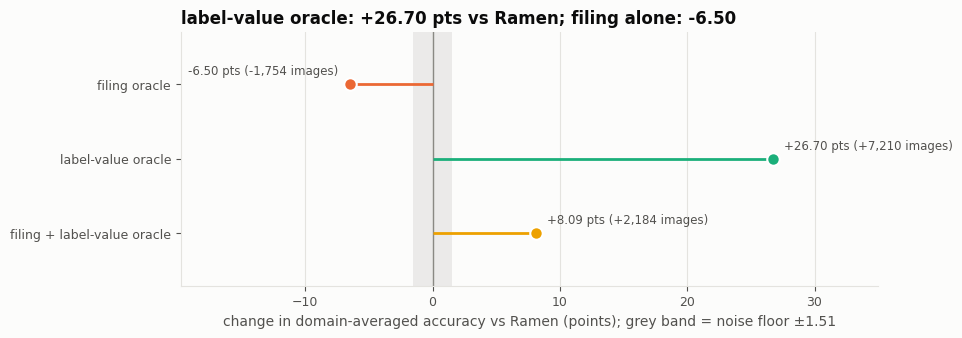

In [8]:
by_run = ft.reset_index().set_index('run')['vs Ramen (pts)']
best = by_run[ORACLES].idxmax()
title = f"{LABELS[best]}: {by_run[best]:+.2f} pts vs Ramen; filing alone: {by_run[FILING]:+.2f}"
plots.plot_vs_ramen(exp, ORACLES, floor, title=title);

### 4.3 Per class

In [9]:
exp.accuracy_table(RUNS, by=BY)

,NoAdapt,Ramen,labeloracle_true_entropy,labeloracle_zs_ce,labeloracle_true_ce
class,,,,,
Annual Crop Land,67.80,91.20,86.53,94.20,71.60
Forest,34.97,72.30,61.73,94.67,86.30
Herbaceous Vegetation Land,6.67,0.30,0.10,88.40,30.97
Highway or Road,71.44,91.92,84.52,91.76,68.04
Industrial Buildings,81.52,88.68,84.40,97.84,85.48
Pasture Land,53.60,46.45,35.25,79.15,60.05
Permanent Crop Land,14.36,19.80,26.56,56.28,25.36
Residential Buildings,95.73,99.33,99.27,96.37,82.43
River,47.00,57.80,53.24,94.08,96.44


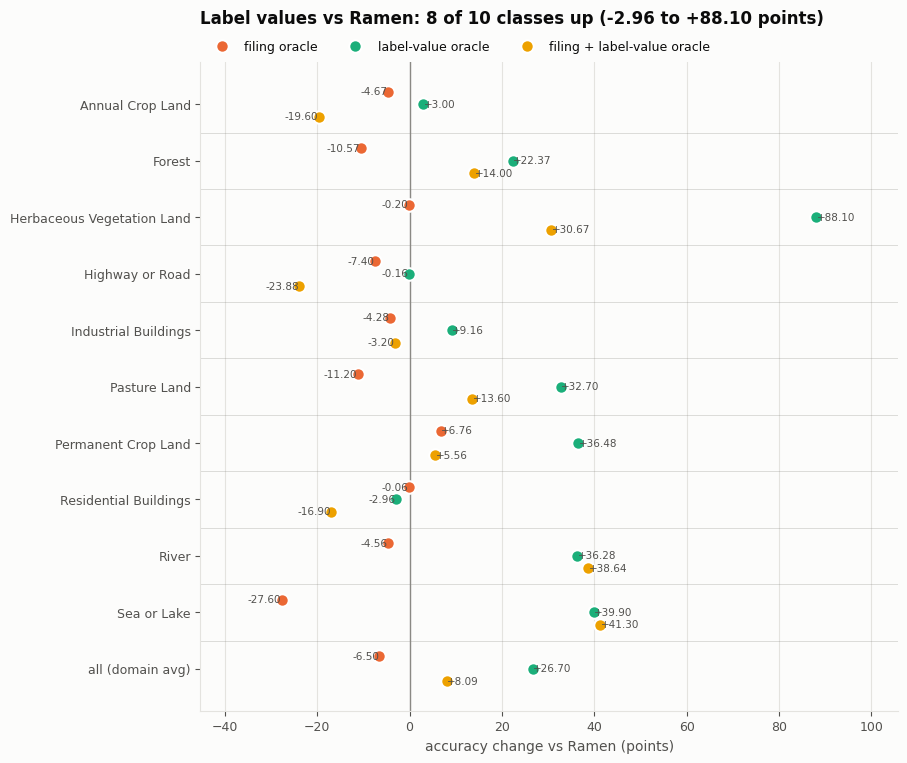

In [10]:
delta = exp.accuracy_table(ORACLES + ['Ramen'], by=BY).iloc[:-1]  # without the average row
gain = delta['labeloracle_zs_ce'] - delta['Ramen']
plots.plot_domain_change(exp, ORACLES, by=BY,
                         title=f"Label values vs Ramen: {(gain > 0).sum()} of {len(gain)} classes up "
                               f"({gain.min():+.2f} to {gain.max():+.2f} points)");

Fixed and broken images vs Ramen for the two label-value runs:

In [11]:
for n in ('labeloracle_zs_ce', 'labeloracle_true_ce'):
    print(LABELS[n])
    display(exp.change_table(n, baseline='Ramen', by=BY))

label-value oracle


,Ramen,labeloracle_zs_ce,images,fixed,broken,net (images),share of net gain
class,,,,,,,
Annual Crop Land,91.20,94.20,3000,189,99,90,1.2%
Forest,72.30,94.67,3000,706,35,671,9.3%
Herbaceous Vegetation Land,0.30,88.40,3000,2643,0,2643,36.7%
Highway or Road,91.92,91.76,2500,133,137,-4,-0.1%
Industrial Buildings,88.68,97.84,2500,240,11,229,3.2%
Pasture Land,46.45,79.15,2000,763,109,654,9.1%
Permanent Crop Land,19.80,56.28,2500,1092,180,912,12.6%
Residential Buildings,99.33,96.37,3000,0,89,-89,-1.2%
River,57.80,94.08,2500,920,13,907,12.6%


filing + label-value oracle


,Ramen,labeloracle_true_ce,images,fixed,broken,net (images),share of net gain
class,,,,,,,
Annual Crop Land,91.20,71.60,3000,122,710,-588,-26.9%
Forest,72.30,86.30,3000,508,88,420,19.2%
Herbaceous Vegetation Land,0.30,30.97,3000,921,1,920,42.1%
Highway or Road,91.92,68.04,2500,127,724,-597,-27.3%
Industrial Buildings,88.68,85.48,2500,215,295,-80,-3.7%
Pasture Land,46.45,60.05,2000,606,334,272,12.5%
Permanent Crop Land,19.80,25.36,2500,458,319,139,6.4%
Residential Buildings,99.33,82.43,3000,4,511,-507,-23.2%
River,57.80,96.44,2500,969,3,966,44.2%


### 4.4 A third filing rule: the adapted prediction

The Ramen paper (Sec. 3.2) and its code file each image under its **zero-shot** prediction. Filing under the
**adapted** prediction instead (Ramen's own output, more often right) needs the write moved *after* prediction,
because the adapted prediction exists only after retrieval and the step (`RamenWriteAfterPrediction`). That also
changes two things besides filing: an image no longer retrieves its own entry or later images of its batch, and
the first batch (empty cache) is predicted zero-shot. So each adapted run has a **timing control**: zero-shot
filing with the same late write.

| run | write | filing | value | uses labels? |
|---|---|---|---|---|
| `late_zs_entropy` | after prediction | zero-shot | entropy | no (timing control for Ramen) |
| `late_zs_ce` | after prediction | zero-shot | true-label CE | oracle (timing control) |
| `late_adapted_entropy` | after prediction | **adapted** | entropy | **no: a method** |
| `late_adapted_ce` | after prediction | **adapted** | true-label CE | oracle |

Checks (`check_write_after.py`, first 3,000 DomainNet images): the first batch is not adapted and equals zero-shot;
retrieval sees earlier batches only; every image is written to the queue of the class the method returned
(adapted filing) or its zero-shot class; 485 of 3,000 images are filed differently by the two rules.

In [12]:
from label_oracle import LATE_RUNS
exp.run_all(LATE_RUNS)
ft3 = exp.filing_table()
ft3

late_zs_entropy: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/EuroSAT_clip_vitbase16_mixed_nall_bs100_s0_late_zs_entropy.pkl
late_zs_ce: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/EuroSAT_clip_vitbase16_mixed_nall_bs100_s0_late_zs_ce.pkl
late_adapted_entropy: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/EuroSAT_clip_vitbase16_mixed_nall_bs100_s0_late_adapted_entropy.pkl
late_adapted_ce: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/EuroSAT_clip_vitbase16_mixed_nall_bs100_s0_late_adapted_ce.pkl


run  uses labels  acc (domain avg)  vs Ramen (pts)  vs Ramen (images)
write                    filing     value                                                                                                    
before retrieval (Ramen) zero-shot  entropy                           Ramen        False             62.63            0.00                  0
                         true label entropy        labeloracle_true_entropy         True             56.13           -6.50              -1754
                         zero-shot  true-label CE         labeloracle_zs_ce         True             89.33           26.70               7210
                         true label true-label CE       labeloracle_true_ce         True             70.72            8.09               2184
after prediction         zero-shot  entropy                 late_zs_entropy        False             63.16            0.53                144
                                    true-label CE                late_zs_ce         True             89.11           26.49               7151
                         adapted    entropy            late_adapted_entropy        False             56.59           -6.04              -1630
                                    true-label CE           late_adapted_ce         True             88.53           25.90               6992

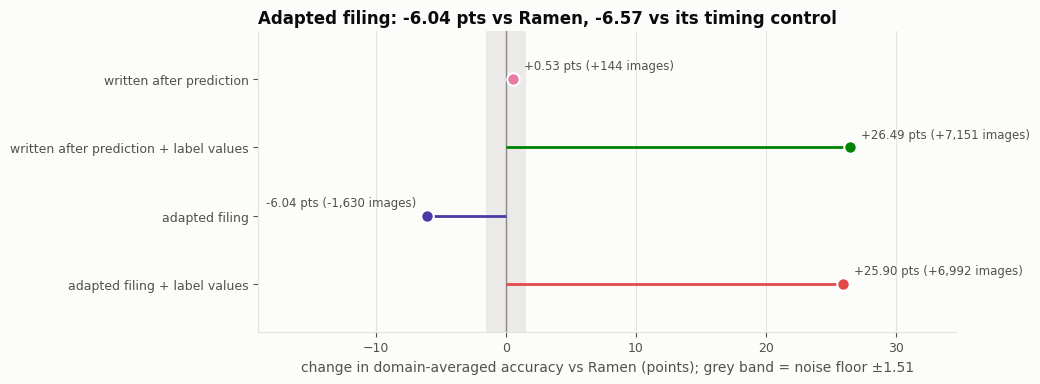

In [13]:
v = ft3.reset_index().set_index('run')['vs Ramen (pts)']
plots.plot_vs_ramen(exp, list(LATE_RUNS), floor,
                    title=f"Adapted filing: {v['late_adapted_entropy']:+.2f} pts vs Ramen, "
                          f"{v['late_adapted_entropy'] - v['late_zs_entropy']:+.2f} vs its timing control");

Per class: Ramen, its timing control, and adapted filing (both with entropy values).

In [14]:
late = exp.accuracy_table(['Ramen', 'late_zs_entropy', 'late_adapted_entropy'], by='class')
late['adapted − timing control'] = late['late_adapted_entropy'] - late['late_zs_entropy']
late.round(2)

,Ramen,late_zs_entropy,late_adapted_entropy,adapted − timing control
class,,,,
Annual Crop Land,91.20,91.10,88.07,-3.03
Forest,72.30,73.13,51.83,-21.30
Herbaceous Vegetation Land,0.30,0.17,0.07,-0.10
Highway or Road,91.92,93.64,87.52,-6.12
Industrial Buildings,88.68,90.08,87.60,-2.48
Pasture Land,46.45,45.50,51.45,5.95
Permanent Crop Land,19.80,21.48,18.16,-3.32
Residential Buildings,99.33,99.33,99.47,0.14
River,57.80,58.52,57.88,-0.64


### 4.5 Global top-k retrieval: is the queue-averaged vote the bottleneck?

Ramen takes the top-k entries of **every** non-empty class queue and averages them, so most of an update comes
from classes the image is not. `RamenGlobalRetrieval` with `retrieval: global_knn` keeps everything else (filing,
values, timing, weights e^(−H)·e^(−β·d)) and instead takes the **k nearest entries of the whole cache**, normalised
by their total weight.

| run | retrieval | value | uses labels? |
|---|---|---|---|
| `labeloracle_zs_ce` | top-k per queue (Ramen) | true-label CE | oracle |
| `global_ce_k10`, `global_ce_k100`, `global_ce_k1000` | k nearest overall | true-label CE | oracle |
| `global_entropy_k100` | 100 nearest overall | entropy | **no: a method** |

Check: with `retrieval: per_class` (`global_off`) the class reproduces Ramen on every smoke image (section 3.1).


In [15]:
from label_oracle import GLOBAL_RUNS
exp.run_all(GLOBAL_RUNS)
gt = exp.vs_table(['labeloracle_zs_ce', *GLOBAL_RUNS], baselines=('Ramen', 'labeloracle_zs_ce'))
gt

global_ce_k10: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/EuroSAT_clip_vitbase16_mixed_nall_bs100_s0_global_ce_k10.pkl
global_ce_k100: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/EuroSAT_clip_vitbase16_mixed_nall_bs100_s0_global_ce_k100.pkl
global_ce_k1000: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/EuroSAT_clip_vitbase16_mixed_nall_bs100_s0_global_ce_k1000.pkl
global_entropy_k100: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/EuroSAT_clip_vitbase16_mixed_nall_bs100_s0_global_entropy_k100.pkl


,label,acc (domain avg),vs Ramen (pts),vs Ramen (images),vs labeloracle_zs_ce (pts),vs labeloracle_zs_ce (images)
run,,,,,,
labeloracle_zs_ce,label-value oracle,89.33,26.70,7210,0.00,0
global_ce_k10,global k=10 + label values,85.74,23.11,6239,-3.60,-971
global_ce_k100,global k=100 + label values,90.22,27.59,7450,0.89,240
global_ce_k1000,global k=1000 + label values,88.54,25.91,6995,-0.80,-215
global_entropy_k100,global k=100 (no labels),55.11,-7.51,-2029,-34.22,-9239


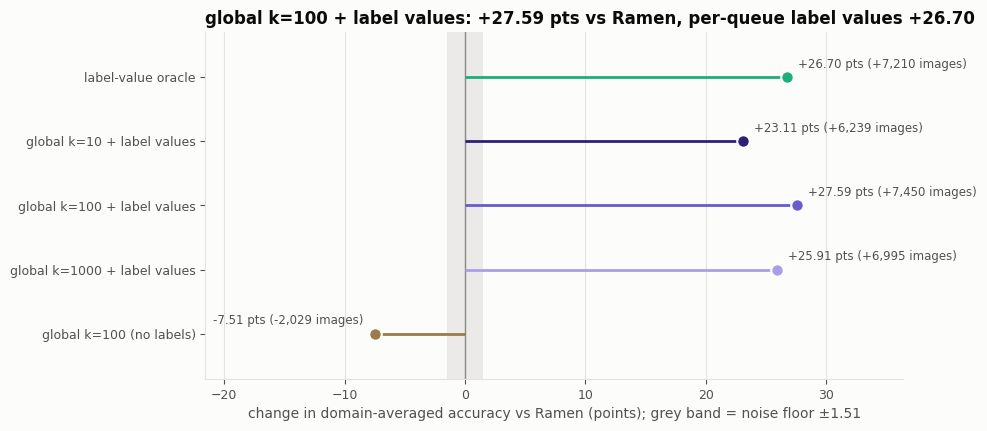

In [16]:
g = gt['vs Ramen (pts)']
best = g[list(GLOBAL_RUNS)].idxmax()
plots.plot_vs_ramen(exp, ['labeloracle_zs_ce', *GLOBAL_RUNS], floor,
                    title=f"{LABELS[best]}: {g[best]:+.2f} pts vs Ramen, per-queue label values "
                          f"{g['labeloracle_zs_ce']:+.2f}");

Per class:

In [17]:
gacc = exp.accuracy_table(['Ramen', 'labeloracle_zs_ce', *GLOBAL_RUNS], by='class')
gacc.round(2)

,Ramen,labeloracle_zs_ce,global_ce_k10,global_ce_k100,global_ce_k1000,global_entropy_k100
class,,,,,,
Annual Crop Land,91.20,94.20,92.40,94.03,92.57,89.03
Forest,72.30,94.67,95.90,96.83,92.57,51.23
Herbaceous Vegetation Land,0.30,88.40,85.63,90.63,85.97,3.03
Highway or Road,91.92,91.76,86.20,89.40,87.12,84.92
Industrial Buildings,88.68,97.84,96.12,98.16,98.12,91.24
Pasture Land,46.45,79.15,86.05,83.95,78.05,47.65
Permanent Crop Land,19.80,56.28,36.08,59.20,60.88,4.92
Residential Buildings,99.33,96.37,98.13,97.80,97.17,98.93
River,57.80,94.08,77.68,90.96,92.88,57.92


## 5. Over-predicted classes

The classes Ramen predicts wrongly most often, and how often each run predicts them wrongly (a sink is a class predicted for many images of other classes).

In [18]:
exp.top_sinks(10)

,truly this class,zero-shot,Ramen,filing oracle,label-value oracle,filing + label-value oracle
class (wrong predictions),,,,,,
Highway or Road,2500,5344,3375,5099,337,1683
Annual Crop Land,3000,2606,2018,2176,946,640
Forest,3000,1805,1598,1491,386,1375
Residential Buildings,3000,1025,865,1130,34,204
Pasture Land,2000,1383,688,466,124,867
Permanent Crop Land,2500,238,608,640,88,661
Industrial Buildings,2500,878,431,576,97,309
Sea or Lake,3000,278,250,118,118,427
River,2500,134,245,145,356,1628


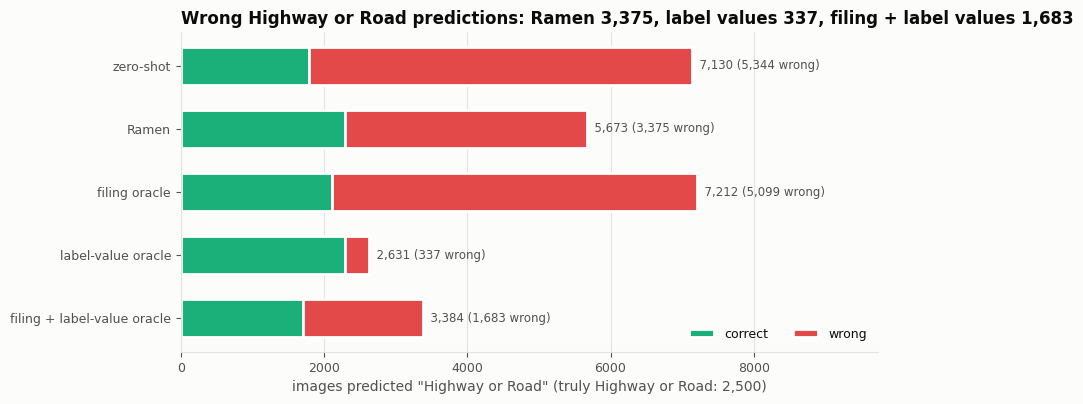

In [19]:
sink = exp.top_sinks(1).index[0]
wrong = exp.top_sinks(1).iloc[0]
plots.plot_class_predictions(exp, sink, RUNS,
                             title=f"Wrong {sink} predictions: Ramen {wrong['Ramen']:,}, label values "
                                   f"{wrong[LABELS['labeloracle_zs_ce']]:,}, filing + label values "
                                   f"{wrong[LABELS['labeloracle_true_ce']]:,}");

## 6. Interpretation

**What the numbers say (seed 0; noise floor 1.51 points).**

| | entropy values (Ramen) | true-label CE values (ORACLE) |
|---|---|---|
| **zero-shot filing (Ramen)** | 62.63 | **89.33 (+26.70, +7,210 images)** |
| **true-label filing (ORACLE)** | 56.13 (−6.50) | 70.72 (+8.09, +2,184 images) |
| **adapted filing, written after prediction** | 56.59 (−6.04) | 88.53 (+25.90) |
| **zero-shot filing, written after prediction (timing control)** | 63.16 (+0.53) | 89.11 (+26.49) |

- **H1 holds, by far.** Label values with Ramen's filing reach 89.33%: +26.70 points, 18 × the floor.
  *Herbaceous Vegetation Land* goes from 0.30% to 88.40%; 8 of 10 classes improve (Residential Buildings −2.96 and
  Highway or Road −0.16 are the exceptions). Ramen's most over-predicted class, *Highway or Road* (3,375 wrong
  predictions), drops to 337.
- **H2 holds.** True-label filing lowers accuracy under both values: −6.50 with entropy values, and +8.09 instead
  of +26.70 with label values (it costs 18.6 points).
- **Adapted filing hurts badly:** −6.04 vs Ramen and −6.57 vs its timing control. *Sea or Lake* falls from 54.63% to
  26.30% and *Forest* from 73.13% to 51.83%. A likely reason (not tested): filing by Ramen's own output feeds its
  over-predictions back into the queues, which with only 10 classes and top-50 retrieval shifts the vote.
- **Timing alone does nothing measurable.** Zero-shot filing with the late write is +0.53 vs Ramen, below the floor.
- EuroSAT's memory never evicts (10 × 7,500 > 27,000): every image is stored, so the label-value runs carry the
  true labels of all earlier images.

**Global retrieval (section 4.5) adds nothing measurable here.** With label values, the 100 nearest entries
overall give +27.59 against +26.70 per queue: a +0.89 difference, below the 1.51 floor. 10 nearest is worse
(+23.11) and 1,000 nearest in between (+25.91). Without labels, global top-100 hurts: −7.51. With 10 classes and
top-50 per queue, Ramen's active set is already 500 entries, so its vote is not spread over many classes as on
DomainNet. EuroSAT has no repeated photos, so the ImageNet-C leak does not apply.

**What it does not show.** One seed; the oracles are upper bounds, not methods. The feedback explanation for
adapted filing is a hypothesis; checking it needs the queue composition over the stream (a cache replay).


## 7. Glossary

| term | meaning |
|---|---|
| zero-shot | CLIP classifies by cosine similarity between the image embedding and each class's text embedding. No adaptation. |
| Ramen | test-time adaptation. Each image is written into a class queue with its own gradient; the gradients of the nearest stored entries are retrieved (top-k per non-empty queue, weighted e^(−H)·e^(−β·d), queues averaged), one signSGD step is taken on the image encoder's LayerNorm parameters, the image is predicted, and the parameters are reset. |
| filing | which queue an image is written to: its zero-shot prediction (Ramen, as in the paper and its code), its true label (oracle), or its adapted prediction (written after prediction). |
| timing control | zero-shot filing with the write moved after prediction: isolates the timing change that adapted filing needs. |
| value | the gradient an entry stores: the image's own entropy gradient (Ramen; sharpens the zero-shot prediction) or the cross-entropy gradient toward its true label (label oracle), stored once the image has been predicted. |
| filing oracle | filed by true label, Ramen's entropy values (`oracle_file_true` or `labeloracle_true_entropy`). |
| label-value oracle | `labeloracle_zs_ce`: filed by zero-shot prediction, label values. |
| filing + label-value oracle | `labeloracle_true_ce`: both. |
| oracle | a run that uses ground-truth labels: an upper bound, not a method. |
| main effect | the change from switching one factor, averaged over the two settings of the other factor. |
| noise floor | 2 × (max − min) of Ramen's domain-averaged accuracy over seeds 0–4; a change must exceed it to count. |
| fixed / broken | images a run gets right that the baseline got wrong / wrong that the baseline got right. |
| domain average | the mean of the per-domain (here per-corruption) accuracies; pooled accuracy for a one-domain dataset. |
| global top-k retrieval | the k nearest entries of the whole cache, whatever their queue (`RamenGlobalRetrieval`, `retrieval: global_knn`), instead of Ramen's top-k of every queue. |
| copies hidden | ImageNet-C only: entries made from another corruption of the query's photo are left out of retrieval (`exclude_groups`); with label values they would carry the query's label. |
